In [1]:
# 1. Load and explore data
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import xgboost as xgb
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('expense_receipts_fraud_detection_2000.csv')
print("Dataset shape:", df.shape)
print("\nFraud distribution:")
print(df['is_fraud'].value_counts(normalize=True))
print("\nFirst 5 rows:")
print(df.head())

Dataset shape: (2000, 12)

Fraud distribution:
is_fraud
0    0.9
1    0.1
Name: proportion, dtype: float64

First 5 rows:
  receipt_id employee_id        date        vendor   location  \
0      R0001       E1001  2025-01-15          Uber     Mumbai   
1      R0002       E1002  2025-01-18     Starbucks  Bangalore   
2      R0003       E1003  2025-02-02    MakeMyTrip      Delhi   
3      R0004       E1004  2025-02-21    Taj Hotels     Mumbai   
4      R0005       E1005  2025-02-23  Office Depot       Pune   

                              items_text  total_amount currency  \
0                       Airport cab ride         850.0      INR   
1                    Latte x2, croissant         520.0      INR   
2                 Flight BLR-DEL economy       11200.0      INR   
3  Conference hotel stay for client meet       10500.0      INR   
4      A4 paper 5 reams, toner cartridge         900.0      INR   

          category payment_method project_code  is_fraud  
0           travel      c

In [3]:
# 2. Feature Engineering
df['date'] = pd.to_datetime(df['date'])
df['amount_log'] = np.log1p(df['total_amount'])  # Log transform skewed amounts // also normalises values between 0 to 10 // log(1+total_amount)
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month

In [4]:
# Create frequency features (fraudsters submit more often)
employee_freq = df.groupby('employee_id').size().to_dict()
df['employee_freq'] = df['employee_id'].map(employee_freq)
print(employee_freq)

vendor_freq = df.groupby('vendor').size().to_dict()
df['vendor_freq'] = df['vendor'].map(vendor_freq)

print(vendor_freq)

{'E100': 1, 'E1001': 60, 'E1002': 53, 'E1003': 50, 'E1004': 48, 'E1005': 61, 'E1006': 46, 'E1007': 51, 'E1008': 54, 'E1009': 53, 'E1010': 64, 'E1011': 50, 'E1012': 71, 'E1013': 47, 'E1014': 47, 'E1015': 53, 'E1016': 46, 'E1017': 47, 'E1018': 54, 'E1019': 47, 'E102': 1, 'E1020': 53, 'E1021': 5, 'E1022': 17, 'E1023': 19, 'E1024': 3, 'E1025': 7, 'E1026': 1, 'E1028': 5, 'E1029': 3, 'E103': 1, 'E1030': 6, 'E1031': 2, 'E1032': 14, 'E1033': 12, 'E1034': 12, 'E1035': 6, 'E1038': 4, 'E1039': 4, 'E104': 1, 'E1040': 7, 'E1041': 6, 'E1042': 8, 'E1043': 2, 'E1044': 8, 'E1045': 15, 'E1047': 8, 'E1048': 4, 'E1049': 3, 'E105': 1, 'E1050': 19, 'E1051': 2, 'E1052': 2, 'E1053': 1, 'E1054': 6, 'E1055': 9, 'E1056': 10, 'E1057': 5, 'E1058': 1, 'E1059': 2, 'E1060': 10, 'E1061': 2, 'E1062': 13, 'E1063': 5, 'E1064': 4, 'E1065': 5, 'E1066': 6, 'E1067': 14, 'E1068': 5, 'E1069': 3, 'E107': 2, 'E1070': 16, 'E1071': 6, 'E1072': 4, 'E1073': 2, 'E1074': 4, 'E1075': 11, 'E1076': 3, 'E1077': 5, 'E1078': 16, 'E1079': 4,

In [5]:
# 3. Prepare features for XGBoost
import pandas as pd 
import numpy as np

features = ['total_amount', 'amount_log', 'year', 'month', 'employee_freq', 'vendor_freq']
cat_features = ['vendor', 'location', 'category', 'payment_method', 'project_code']
for col in cat_features:
    le = LabelEncoder()
    df[col + '_encoded'] = le.fit_transform(df[col])
    features.append(col + '_encoded')

X = df[features]
y = df['is_fraud']

print("\nFeatures created:", features)
print("X shape:", X.shape)





Features created: ['total_amount', 'amount_log', 'year', 'month', 'employee_freq', 'vendor_freq', 'vendor_encoded', 'location_encoded', 'category_encoded', 'payment_method_encoded', 'project_code_encoded']
X shape: (2000, 11)


🔧 Auto-creating features...


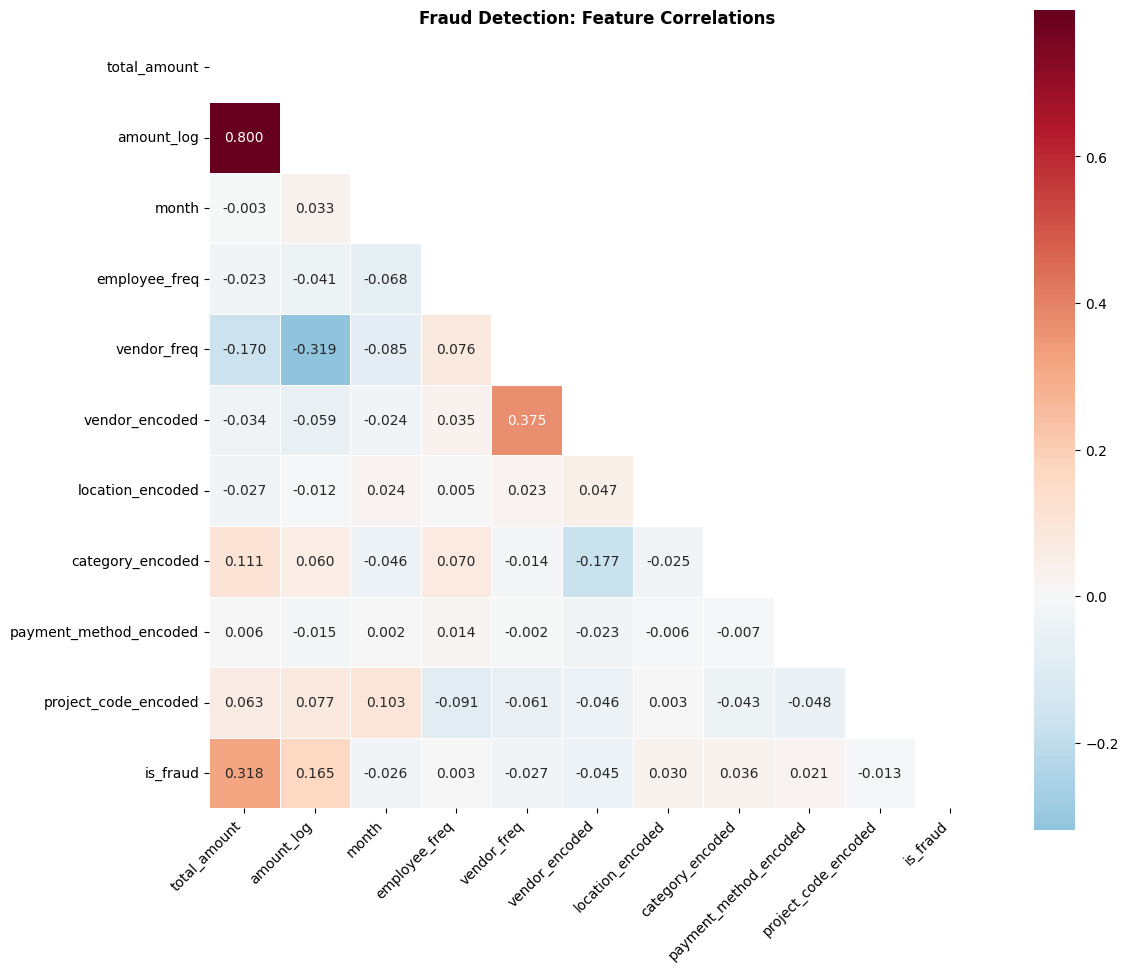

✅ HEATMAP COMPLETE

🚨 FRAUD CORRELATIONS (Top 5):
is_fraud            1.000
total_amount        0.318
amount_log          0.165
category_encoded    0.036
location_encoded    0.030
Name: is_fraud, dtype: float64


In [6]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
import seaborn as sns
import matplotlib.pyplot as plt

# Safe feature list from YOUR CSV
raw_features = ['total_amount', 'employee_id', 'vendor', 'location', 'category', 
                'payment_method', 'project_code', 'date', 'is_fraud']

# Create ALL features safely
print("🔧 Auto-creating features...")
df = df[raw_features].copy()  # Clean start

# Date features
df['date'] = pd.to_datetime(df['date'])
df['month'] = df['date'].dt.month
df['amount_log'] = np.log1p(df['total_amount'])

# Frequency features
df['employee_freq'] = df['employee_id'].map(df['employee_id'].value_counts())
df['vendor_freq'] = df['vendor'].map(df['vendor'].value_counts())

# Categorical encoding (safe - skips if exists)
cat_features = ['vendor', 'location', 'category', 'payment_method', 'project_code']
for col in cat_features:
    if col + '_encoded' not in df.columns:
        le = LabelEncoder()
        df[col + '_encoded'] = le.fit_transform(df[col].astype(str))

# Numeric features only
numeric_features = ['total_amount', 'amount_log', 'month', 'employee_freq', 
                    'vendor_freq', 'vendor_encoded', 'location_encoded', 
                    'category_encoded', 'payment_method_encoded', 'project_code_encoded']

# Build correlation (only existing columns)
available_features = [f for f in numeric_features if f in df.columns]
features_with_target = available_features + ['is_fraud']
corr = df[features_with_target].corr()

# HEATMAP
plt.figure(figsize=(12, 10))
mask = np.triu(np.ones_like(corr, dtype=bool))  # Upper triangle mask
sns.heatmap(corr, annot=True, cmap='RdBu_r', center=0, fmt='.3f', 
            mask=mask, square=True, linewidths=0.5)
plt.title('Fraud Detection: Feature Correlations', fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print("✅ HEATMAP COMPLETE")
print("\n🚨 FRAUD CORRELATIONS (Top 5):")
print(corr['is_fraud'].sort_values(ascending=False).head().round(3))


In [7]:
# 4. Train-test split (stratified to preserve 10% fraud ratio)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
print(f"Train fraud rate: {y_train.mean():.2%}, Test fraud rate: {y_test.mean():.2%}")

Train fraud rate: 10.00%, Test fraud rate: 10.00%


In [8]:
import xgboost
print(xgboost.__version__)

3.2.0


In [9]:
from tensorflow.keras.callbacks import EarlyStopping
import xgboost as xgb


# 5. Train XGBoost (handles imbalance automatically)
model = xgb.XGBClassifier(
    early_stopping_rounds=20,
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    scale_pos_weight=9,  # 1800/200 = 9 (balance classes)
    random_state=42,
    eval_metric='aucpr'  # Precision-recall AUC for imbalanced data
)

model.fit(
    X=X_train,
    y=y_train,
    eval_set=[(X_test, y_test)],
    #callbacks=[xgb.callback.EarlyStopping(rounds=20)],
    verbose=False
)


,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",20
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes fr

In [10]:
# # 6. Predictions and evaluation
# y_pred = model.predict(X_test)
# y_pred_proba = model.predict_proba(X_test)[:, 1]

# print("\n=== MODEL PERFORMANCE ===")
# print(classification_report(y_test, y_pred))
# print(f"ROC-AUC: {roc_auc_score(y_test, y_pred_proba):.3f}")

# # Confusion Matrix
# cm = confusion_matrix(y_test, y_pred)
# sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
# plt.title('Confusion Matrix')
# plt.ylabel('Actual')
# plt.xlabel('Predicted')
# plt.show()

In [11]:
# # 7. Feature Importance (WHICH PATTERNS DETECT FRAUD?)
# xgb.plot_importance(model, max_num_features=10)
# plt.title('Top 10 Fraud Indicators')
# plt.tight_layout()
# plt.show()

In [12]:
# # 8. Predict on ALL data + Export flagged frauds
# df['fraud_pred'] = model.predict(X)
# df['fraud_prob'] = model.predict_proba(X)[:, 1]

# flagged_frauds = df[df['fraud_pred'] == 1].sort_values('fraud_prob', ascending=False)
# print("\n=== TOP 10 FLAGGED FRAUDS ===")
# print(flagged_frauds[['receipt_id', 'vendor', 'total_amount', 'category', 'fraud_prob']].head(10))

In [13]:
# # Export results
# df.to_csv('expense_reports_with_predictions.csv', index=False)
# flagged_frauds.to_csv('flagged_frauds.csv', index=False)
# print("\n✅ Saved: expense_reports_with_predictions.csv")
# print("✅ Saved: flagged_frauds.csv (for managers)")

Shape: (2000, 12)

Fraud distribution (counts):
is_fraud
0    1800
1     200
Name: count, dtype: int64

Fraud distribution (ratio):
is_fraud
0    0.9
1    0.1
Name: proportion, dtype: float64

Head:
  receipt_id employee_id        date        vendor   location  \
0      R0001       E1001  2025-01-15          Uber     Mumbai   
1      R0002       E1002  2025-01-18     Starbucks  Bangalore   
2      R0003       E1003  2025-02-02    MakeMyTrip      Delhi   
3      R0004       E1004  2025-02-21    Taj Hotels     Mumbai   
4      R0005       E1005  2025-02-23  Office Depot       Pune   

                              items_text  total_amount currency  \
0                       Airport cab ride         850.0      INR   
1                    Latte x2, croissant         520.0      INR   
2                 Flight BLR-DEL economy       11200.0      INR   
3  Conference hotel stay for client meet       10500.0      INR   
4      A4 paper 5 reams, toner cartridge         900.0      INR   

       

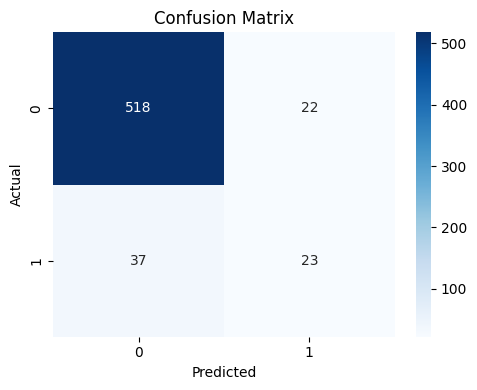


=== Top 20 suspicious ===
     receipt_id employee_id           vendor              category  \
870       R0871       E1075            Regus       office_supplies   
240       R0241       E1012             Uber                travel   
1447      R1448       E1021              OYO         accommodation   
1699      R1700       E1041             Uber                travel   
360       R0361       E1003       MakeMyTrip                travel   
1871      R1872       E1012             Uber  client_entertainment   
1445      R1446       E1133            Croma       office_supplies   
111       R0112       E1065        Starbucks                 meals   
1361      R1362       E1095        Starbucks                 meals   
1731      R1732       E1012  Gourmet Kitchen  client_entertainment   
1978      R1979       E1019             Uber                travel   
1466      R1467       E1007        Air India                travel   
1184      R1185       E1005            Croma       office_suppl

In [14]:
# ===================== XGBOOST FRAUD DETECTION (COMPLETE) =====================

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, average_precision_score

import xgboost as xgb

import matplotlib.pyplot as plt
import seaborn as sns


# 1) Load dataset
df = pd.read_csv("expense_receipts_fraud_detection_2000.csv")

print("Shape:", df.shape)
print("\nFraud distribution (counts):")
print(df["is_fraud"].value_counts())
print("\nFraud distribution (ratio):")
print(df["is_fraud"].value_counts(normalize=True))
print("\nHead:")
print(df.head())


# 2) Basic cleaning + date features
df["date"] = pd.to_datetime(df["date"], errors="coerce")

df["year"] = df["date"].dt.year.fillna(0).astype(int)
df["month"] = df["date"].dt.month.fillna(0).astype(int)
df["day"] = df["date"].dt.day.fillna(0).astype(int)
df["dayofweek"] = df["date"].dt.dayofweek.fillna(0).astype(int)

# Numeric transforms
df["total_amount"] = pd.to_numeric(df["total_amount"], errors="coerce").fillna(0.0)
df["amount_log"] = np.log1p(df["total_amount"])

# Text length feature (simple but useful)
df["items_len"] = df["items_text"].fillna("").astype(str).str.len()


# 3) Frequency features (how common employee/vendor is)
df["employee_freq"] = df.groupby("employee_id")["receipt_id"].transform("count")
df["vendor_freq"] = df.groupby("vendor")["receipt_id"].transform("count")
df["project_freq"] = df.groupby("project_code")["receipt_id"].transform("count")


# 4) Build X and y
target = "is_fraud"

cat_cols = ["employee_id", "vendor", "location", "currency", "category", "payment_method", "project_code"]
num_cols = ["total_amount", "amount_log", "items_len", "employee_freq", "vendor_freq", "project_freq",
            "year", "month", "day", "dayofweek"]

# Encode categoricals safely (handles unseen categories in test)
enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
X_cat = enc.fit_transform(df[cat_cols].fillna("NA"))

X_num = df[num_cols].astype(float).values
X = np.hstack([X_num, X_cat])

y = df[target].astype(int).values

print("\nFeature matrix shape:", X.shape)


# 5) Train-test split (stratified because fraud is minority)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# Class imbalance weight: (neg/pos)
pos = (y_train == 1).sum()
neg = (y_train == 0).sum()
scale_pos_weight = neg / max(pos, 1)
print(f"\nTrain pos={pos}, neg={neg}, scale_pos_weight={scale_pos_weight:.2f}")


# 6) Train XGBoost
model = xgb.XGBClassifier(
    early_stopping_rounds=20,
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.9,
    reg_lambda=1.0,
    random_state=42,
    scale_pos_weight=scale_pos_weight,
    eval_metric="aucpr",          # good for imbalanced data
    tree_method="hist"            # fast on CPU
)

model.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    verbose=False,
    
)


# 7) Evaluate
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

print("\n=== Classification report ===")
print(classification_report(y_test, y_pred, digits=4))

print("ROC-AUC:", roc_auc_score(y_test, y_proba))
print("PR-AUC (Average Precision):", average_precision_score(y_test, y_proba))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()


# 8) Add predictions to full dataframe + export
df["fraud_prob"] = model.predict_proba(X)[:, 1]
df["fraud_pred"] = (df["fraud_prob"] >= 0.5).astype(int)

# Top suspicious receipts
top = df.sort_values("fraud_prob", ascending=False).head(20)
print("\n=== Top 20 suspicious ===")
print(top[["receipt_id", "employee_id", "vendor", "category", "total_amount", "payment_method", "fraud_prob"]])

df.to_csv("expense_reports_with_predictions.csv", index=False)
top.to_csv("top20_suspicious.csv", index=False)

print("\nSaved files:")
print("- expense_reports_with_predictions.csv")
print("- top20_suspicious.csv")


In [15]:
# ========== SAVE MODEL + ENCODERS (Cell after model.fit()) ==========
import pickle
import joblib  # For encoders

# 1. Save XGBoost model
pickle.dump(model, open('fraud_xgb_model.pkl', 'wb'))
print("✅ XGBoost model saved: fraud_xgb_model.pkl")

# 2. Save encoders (from your cat_features loop)
encoders = {}
for col in ['vendor', 'location', 'category', 'payment_method', 'project_code']:
    encoders[col] = le  # Your LabelEncoder from loop
    joblib.dump(le, f'{col}_encoder.pkl')

print("✅ Encoders saved for Streamlit")

# 3. Quick test load
loaded_model = pickle.load(open('fraud_xgb_model.pkl', 'rb'))
print("✅ Model loads OK:", loaded_model)


✅ XGBoost model saved: fraud_xgb_model.pkl
✅ Encoders saved for Streamlit
✅ Model loads OK: XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.9, device=None, early_stopping_rounds=20,
              enable_categorical=False, eval_metric='aucpr', feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.05, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=500,
              n_jobs=None, num_parallel_tree=None, ...)
